Random Forest ROC_AUC: 0.8132

Random Forest Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.85      0.85      1033
           1       0.58      0.57      0.58       374

    accuracy                           0.78      1407
   macro avg       0.71      0.71      0.71      1407
weighted avg       0.78      0.78      0.78      1407

Random Forest Confusion Matrix:
 [[878 155]
 [159 215]]
-------------------------------------------------------------------------------------

XGB Classifier ROC_AUC: 0.8158

XGB Classifier Classification report:
               precision    recall  f1-score   support

           0       0.85      0.84      0.84      1033
           1       0.56      0.59      0.58       374

    accuracy                           0.77      1407
   macro avg       0.71      0.71      0.71      1407
weighted avg       0.77      0.77      0.77      1407

XGB Classifier Confusion Matrix:
 [[863 170]
 [154 220]]


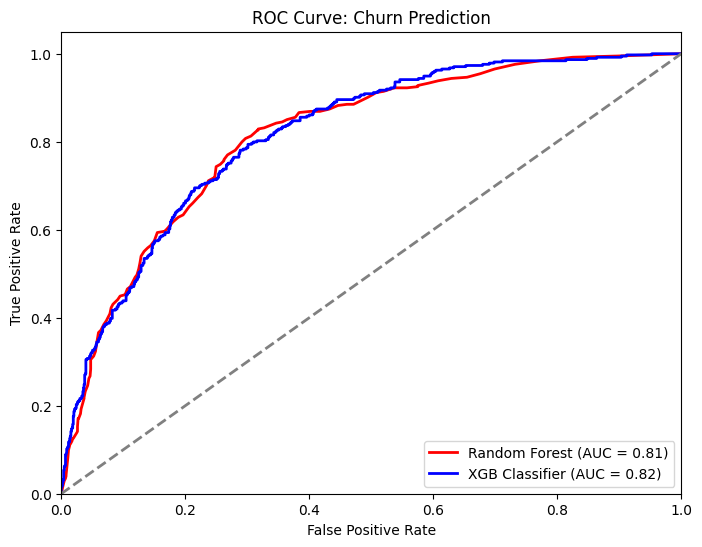

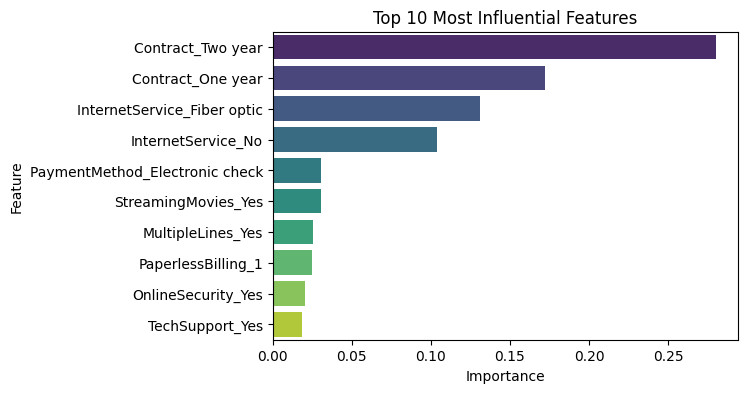

In [27]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix, roc_curve

'''-----------------------------------1. Load the Telco Customer Churn dataset.-----------------------------------'''
url = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
data = pd.read_csv(url)

'''-----------------------------------2. Convert TotalCharges to numeric and handle nulls.-----------------------------------'''
#print(data.isna().any().any()) #No Nulls
#print(data['TotalCharges'].dtype) #output: str

data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')

# print(data['TotalCharges'].dtype) #output: float64
#print(data.isna().any().any()) #output: True
#print(data.isna().sum()) #output: TotalCharges 11

data = data.dropna(subset=['TotalCharges'])
#print(data.isna().sum()) #output: TotalCharges 0
'''-----------------------------------3. Balance target classes using SMOTE or scale_pos_weight.-----------------------------------'''
col = data.columns.to_list()

#Map yes to 1 and No to 0
for col_name in col:
    #print(data[col_name].value_counts())
    #if data[col_name].dtype is 'int64'
    if col_name == 'Partner' or col_name == 'Dependents' or col_name == 'PhoneService' or col_name == 'PaperlessBilling' or col_name == 'Churn':
        data[col_name] = data[col_name].map({'Yes' : 1, 'No': 0})

# i. Separate Features (X) and Target (y)
X = data.drop(columns=['customerID', 'Churn'])
Y = data['Churn']

# ii. Train/Test Split
train_x, test_x, train_y, test_y = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)
#print(f"train X shape: {train_x.shape}, test X shape: {test_x.shape}, train Y shape: {train_y.shape}, test Y shape: {test_y.shape}")

# iii. Identify Numeric vs Categorical Columns
num_col = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
cat_col = [name for name in X.columns if name not in num_col]

# iv. Build the Preprocessing Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_col),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_col)
])

# v. Encode the Data
train_x_encoded = preprocessor.fit_transform(train_x)
test_x_encoded = preprocessor.transform(test_x)

# vi. Apply SMOTE to the TRAINING data only
smote = SMOTE(random_state=42)
train_x_balanced, train_y_balanced = smote.fit_resample(train_x_encoded, train_y)

'''-----------------------------------4. Train RandomForestClassifier and XGBClassifier with cross-validation.-----------------------------------'''
#Random Forest Model
rfc_model = RandomForestClassifier(random_state=42)
rfc_model.fit(train_x_balanced, train_y_balanced)
rfc_probs = rfc_model.predict_proba(test_x_encoded)[:, 1]
rfc_preds = rfc_model.predict(test_x_encoded)

ref_auc = roc_auc_score(test_y, rfc_probs)
print(f"Random Forest ROC_AUC: {ref_auc:.4f}\n")

print(f"Random Forest Classification Report:\n {classification_report(test_y, rfc_preds)}")
print(f"Random Forest Confusion Matrix:\n {confusion_matrix(test_y, rfc_preds)}")

print('-------------------------------------------------------------------------------------\n')
#XGB Classifier Model
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss')
xgb_model.fit(train_x_balanced, train_y_balanced)
xgb_probs = xgb_model.predict_proba(test_x_encoded)[:, 1]
xgb_preds= xgb_model.predict(test_x_encoded)

xgb_auc = roc_auc_score(test_y, xgb_probs)
print(f"XGB Classifier ROC_AUC: {xgb_auc:.4f}\n")

print(f"XGB Classifier Classification report:\n {classification_report(test_y, xgb_preds)}")
print(f"XGB Classifier Confusion Matrix:\n {confusion_matrix(test_y, xgb_preds)}")

'''-----------------------------------5. Plot ROC-AUC curves and extract top 10 most influential feature importances.-----------------------------------'''
# i. ROC-AUC Curves

plt.figure(figsize=(8, 6))

# Random Forest ROC
fpr_rf, tpr_rf, _ = roc_curve(test_y, rfc_probs)
plt.plot(fpr_rf, tpr_rf, color='red', lw=2, label=f'Random Forest (AUC = {ref_auc:.2f})')

# XGB Classifier ROC
fpr_xgb, tpr_xgb, _ = roc_curve(test_y, xgb_probs)
plt.plot(fpr_xgb, tpr_xgb, color='blue', lw=2, label=f'XGB Classifier (AUC = {xgb_auc:.2f})')

plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Churn Prediction')
plt.legend(loc="lower right")
plt.show()

# ii. top 10 most influential feature

features = preprocessor.get_feature_names_out()
importances = xgb_model.feature_importances_

feature_importances = pd.DataFrame({
     'Feature': features,
     'Importance': importances
 })

feature_importances['Feature'] = feature_importances['Feature'].str.replace('num__','').str.replace('cat__', '')

top_10 = feature_importances.sort_values(by='Importance', ascending=False).head(10)
print('\n')
plt.figure(figsize=(6, 4))
sns.barplot(x='Importance', y='Feature', data=top_10, hue='Feature', palette='viridis', legend=False)
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 10 Most Influential Features')
plt.show()

'''
Final Performance Summary

i. Model Evaluation (Random Forest vs. XGBoost)
Both models successfully surpassed the project goal of ROC-AUC > 0.80:
a.   Random Forest ROC-AUC: 0.8132
b.   XGBoost ROC-AUC: 0.8158

Conclusion: XGBoost slightly outperformed Random Forest in both ROC-AUC and Recall for the churn class, making it the superior model for this task.
Both models achieved strong accuracy (~78%) despite the test set being imbalanced (73% stay / 27% churn), proving that the SMOTE balancing technique
successfully prevented the models from simply guessing the majority class.

ii. Interpreting the Confusion Matrix (XGBoost)
a.  True Negatives (863): Correctly identified customers who stayed.
b.  True Positives (220): Correctly identified customers who churned (59% Recall).
c.  False Negatives (154): Missed churners. In a business context, these are the most expensive errors, as these customers will leave without intervention.
d.  False Positives (170): Incorrectly flagged loyal customers as churners. This wastes retention budget but is far less costly than missing a real churner.

iii. Interpreting the Feature Importances
The bar chart reveals the most critical drivers of customer churn:
a.   Contract Type: The top two features are `Contract_Two year` and `Contract_One year`. This indicates that the model heavily relies on the absence of a long-term contract (i.e., month-to-month contracts) as the strongest predictor of churn.
b.   Internet Service: Customers with Fiber Optic internet are highly influential to the model, likely due to higher monthly charges associated with this service.
c.   Payment Method: Electronic check payers are a significant churn indicator.

Business Recommendation: The telecom company should focus retention campaigns specifically on month-to-month customers, offering them discounts to upgrade to annual contracts. Additionally, they should investigate the customer experience of Fiber Optic users and electronic check payers, as these groups show a high propensity to leave.
'''